# Lab 2 — Partie 1 : CNN classifier pour MNIST

Notebook PyTorch destiné à Kaggle avec GPU (T4). Il entraîne un CNN, suit la perte et l’accuracy sur validation, conserve le meilleur modèle et applique l’early stopping. Le jeu de test n’est utilisé qu’à la fin.

**Avant de lancer :** dans Kaggle, ajoute le dataset `hojjatk/mnist-dataset` via **Add Input**, puis active **Settings → Accelerator → GPU T4**.


In [8]:
from pathlib import Path
import os, gzip, shutil, random, copy, time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

if not torch.cuda.is_available():
    raise RuntimeError("GPU non disponible. Activez GPU T4 dans les paramètres du notebook Kaggle.")
device = torch.device("cuda")
print("GPU :", torch.cuda.get_device_name(0))
print("Entrées Kaggle :", [str(p) for p in Path('/kaggle/input').iterdir()])


GPU : Tesla T4
Entrées Kaggle : ['/kaggle/input/datasets']


## Préparer les fichiers MNIST

Cette cellule recherche automatiquement les quatre fichiers IDX classiques dans `/kaggle/input`, qu’ils soient compressés en `.gz` ou non, puis les place dans le dossier attendu par torchvision.


In [9]:
required = [
    'train-images-idx3-ubyte', 'train-labels-idx1-ubyte',
    't10k-images-idx3-ubyte', 't10k-labels-idx1-ubyte'
]
input_root = Path('/kaggle/input')
raw_dir = Path('/kaggle/working/MNIST/raw')
raw_dir.mkdir(parents=True, exist_ok=True)

all_files = [p for p in input_root.rglob('*') if p.is_file()]
for name in required:
    candidates = [p for p in all_files if p.name in (name, name + '.gz')]
    if not candidates:
        raise FileNotFoundError(
            f"Impossible de trouver {name} (ou {name}.gz) sous /kaggle/input. "
            "Vérifiez que le dataset MNIST est attaché au notebook."
        )
    src = candidates[0]
    dst = raw_dir / name
    if src.name.endswith('.gz'):
        with gzip.open(src, 'rb') as f_in, open(dst, 'wb') as f_out:
            shutil.copyfileobj(f_in, f_out)
    else:
        shutil.copy2(src, dst)
    print(f"{src.name} → {dst}")


train-images-idx3-ubyte → /kaggle/working/MNIST/raw/train-images-idx3-ubyte
train-labels-idx1-ubyte → /kaggle/working/MNIST/raw/train-labels-idx1-ubyte
t10k-images-idx3-ubyte → /kaggle/working/MNIST/raw/t10k-images-idx3-ubyte
t10k-labels-idx1-ubyte → /kaggle/working/MNIST/raw/t10k-labels-idx1-ubyte


## Charger et séparer les données

La validation contient 6 000 images du train officiel. Les transformations aléatoires légères ne sont appliquées qu’aux images d’entraînement.


In [10]:
train_transform = transforms.Compose([
    transforms.RandomAffine(degrees=8, translate=(0.08, 0.08)),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Deux instances distinctes permettent d'appliquer des transforms différents
full_train_aug = datasets.MNIST('/kaggle/working', train=True, download=False, transform=train_transform)
full_train_eval = datasets.MNIST('/kaggle/working', train=True, download=False, transform=eval_transform)
indices = torch.randperm(len(full_train_aug), generator=torch.Generator().manual_seed(SEED)).tolist()
val_size = 6000
val_indices, train_indices = indices[:val_size], indices[val_size:]

train_set = torch.utils.data.Subset(full_train_aug, train_indices)
val_set = torch.utils.data.Subset(full_train_eval, val_indices)
test_set = datasets.MNIST('/kaggle/working', train=False, download=False, transform=eval_transform)

BATCH_SIZE = 128
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
print(f"Train: {len(train_set)} | validation: {len(val_set)} | test: {len(test_set)}")


Train: 54000 | validation: 6000 | test: 10000


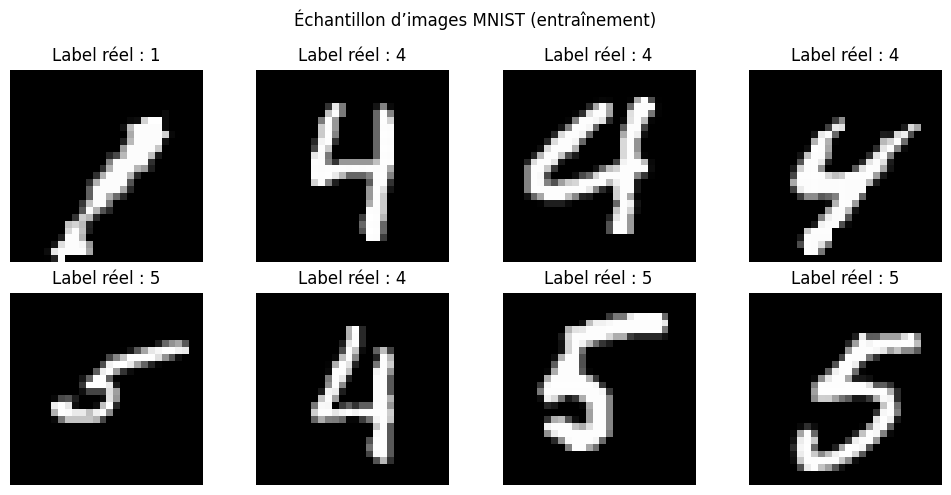

In [11]:
import matplotlib.pyplot as plt

# Échantillon de 8 images du jeu d'entraînement
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, image, label in zip(axes.flat, images[:8], labels[:8]):
    # Annuler la normalisation pour afficher l'image en niveaux de gris
    image_to_show = image.squeeze(0) * 0.3081 + 0.1307
    ax.imshow(image_to_show.numpy(), cmap='gray')
    ax.set_title(f"Label réel : {label.item()}")
    ax.axis('off')
plt.suptitle('Échantillon d’images MNIST (entraînement)')
plt.tight_layout()
plt.show()


## Définir le CNN

Le réseau utilise trois convolutions, BatchNorm, ReLU, max pooling, dropout et deux couches entièrement connectées. La dernière couche renvoie 10 logits, un par chiffre.


In [12]:
class MNIST_CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),                    # 32 x 14 x 14
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),                    # 64 x 7 x 7
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.Dropout2d(0.15)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.40),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = MNIST_CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)
print(model)


MNIST_CNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Dropout2d(p=0.15, inplace=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6272, out_features=128, bias=True)
    (2): ReLU(inplace=True)
    (3): 

## Entraînement avec early stopping

Le meilleur état du modèle est choisi sur la perte de validation. L’entraînement s’arrête après plusieurs époques sans amélioration.


In [13]:
def run_epoch(loader, training=False):
    model.train(training)
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total

EPOCHS = 30
PATIENCE = 6
best_val_loss = float('inf')
best_state = None
no_improve = 0
history = []
start = time.time()

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss, val_acc = run_epoch(val_loader, training=False)
    scheduler.step(val_loss)
    history.append((epoch, train_loss, train_acc, val_loss, val_acc))
    print(f"Epoch {epoch:02d} | train loss {train_loss:.4f}, acc {train_acc:.4f} | val loss {val_loss:.4f}, acc {val_acc:.4f}")
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        no_improve = 0
    else:
        no_improve += 1
    if no_improve >= PATIENCE:
        print('Early stopping.')
        break

model.load_state_dict(best_state)
training_seconds = time.time() - start
print(f"Temps d'entraînement : {training_seconds:.1f} secondes")


Epoch 01 | train loss 0.2388, acc 0.9249 | val loss 0.0605, acc 0.9793
Epoch 02 | train loss 0.1039, acc 0.9687 | val loss 0.0347, acc 0.9887
Epoch 03 | train loss 0.0849, acc 0.9747 | val loss 0.0416, acc 0.9883
Epoch 04 | train loss 0.0741, acc 0.9783 | val loss 0.0312, acc 0.9902
Epoch 05 | train loss 0.0644, acc 0.9815 | val loss 0.0255, acc 0.9923
Epoch 06 | train loss 0.0606, acc 0.9816 | val loss 0.0323, acc 0.9903
Epoch 07 | train loss 0.0560, acc 0.9834 | val loss 0.0305, acc 0.9913
Epoch 08 | train loss 0.0506, acc 0.9849 | val loss 0.0318, acc 0.9912
Epoch 09 | train loss 0.0397, acc 0.9887 | val loss 0.0203, acc 0.9942
Epoch 10 | train loss 0.0356, acc 0.9895 | val loss 0.0219, acc 0.9933
Epoch 11 | train loss 0.0360, acc 0.9892 | val loss 0.0196, acc 0.9943
Epoch 12 | train loss 0.0330, acc 0.9899 | val loss 0.0220, acc 0.9937
Epoch 13 | train loss 0.0334, acc 0.9900 | val loss 0.0174, acc 0.9945
Epoch 14 | train loss 0.0309, acc 0.9905 | val loss 0.0193, acc 0.9947
Epoch 

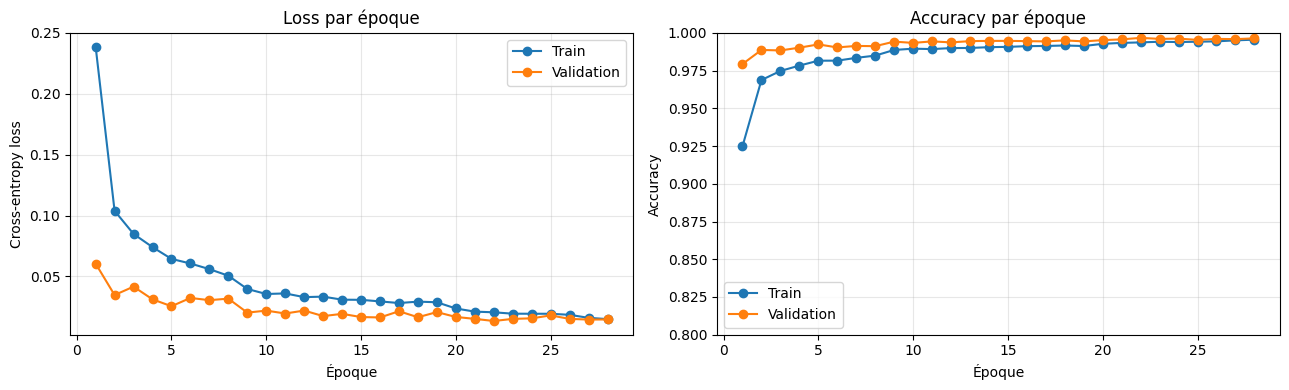

In [14]:
# Tracer loss et accuracy pour entraînement et validation
epochs = [row[0] for row in history]
train_losses = [row[1] for row in history]
train_accuracies = [row[2] for row in history]
val_losses = [row[3] for row in history]
val_accuracies = [row[4] for row in history]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(epochs, train_losses, marker='o', label='Train')
axes[0].plot(epochs, val_losses, marker='o', label='Validation')
axes[0].set_title('Loss par époque')
axes[0].set_xlabel('Époque')
axes[0].set_ylabel('Cross-entropy loss')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(epochs, train_accuracies, marker='o', label='Train')
axes[1].plot(epochs, val_accuracies, marker='o', label='Validation')
axes[1].set_title('Accuracy par époque')
axes[1].set_xlabel('Époque')
axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0.8, 1.0)
axes[1].grid(True, alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()


## Évaluation finale sur le jeu de test

Accuracy, F1 macro, perte et rapport par classe sont calculés avec le meilleur modèle sauvegardé.


In [15]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

model.eval()
all_preds, all_labels = [], []
test_loss_total, n_test = 0.0, 0
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        labels_gpu = labels.to(device, non_blocking=True)
        logits = model(images)
        loss = criterion(logits, labels_gpu)
        test_loss_total += loss.item() * labels.size(0)
        n_test += labels.size(0)
        all_preds.extend(logits.argmax(1).cpu().tolist())
        all_labels.extend(labels.tolist())

test_loss = test_loss_total / n_test
test_accuracy = accuracy_score(all_labels, all_preds)
test_f1_macro = f1_score(all_labels, all_preds, average='macro')
print(f"Temps d'entraînement : {training_seconds:.1f} s")
print(f"Test loss            : {test_loss:.4f}")
print(f"Test accuracy        : {test_accuracy:.4f}")
print(f"Test F1 macro        : {test_f1_macro:.4f}")
print('\nRapport par classe :')
print(classification_report(all_labels, all_preds, digits=4))

model_path = '/kaggle/working/mnist_cnn_best.pth'
torch.save(model.state_dict(), model_path)
print('Modèle sauvegardé :', model_path)


Temps d'entraînement : 339.7 s
Test loss            : 0.0125
Test accuracy        : 0.9956
Test F1 macro        : 0.9956

Rapport par classe :
              precision    recall  f1-score   support

           0     0.9949    0.9969    0.9959       980
           1     0.9956    0.9982    0.9969      1135
           2     0.9923    0.9981    0.9952      1032
           3     0.9951    0.9990    0.9970      1010
           4     0.9939    0.9969    0.9954       982
           5     0.9955    0.9933    0.9944       892
           6     0.9969    0.9916    0.9942       958
           7     0.9961    0.9951    0.9956      1028
           8     0.9990    0.9949    0.9969       974
           9     0.9970    0.9911    0.9940      1009

    accuracy                         0.9956     10000
   macro avg     0.9956    0.9955    0.9956     10000
weighted avg     0.9956    0.9956    0.9956     10000

Modèle sauvegardé : /kaggle/working/mnist_cnn_best.pth


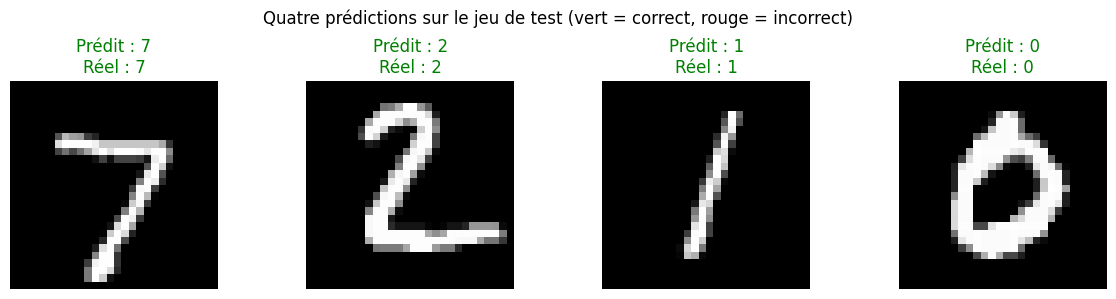

In [16]:
# Afficher quatre images du test et la prédiction du modèle
images, labels = next(iter(test_loader))
images_gpu = images[:4].to(device)
with torch.no_grad():
    predictions = model(images_gpu).argmax(dim=1).cpu()

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i, ax in enumerate(axes):
    image_to_show = images[i].squeeze(0) * 0.3081 + 0.1307
    pred = predictions[i].item()
    true = labels[i].item()
    color = 'green' if pred == true else 'red'
    ax.imshow(image_to_show.numpy(), cmap='gray')
    ax.set_title(f"Prédit : {pred}\nRéel : {true}", color=color)
    ax.axis('off')
plt.suptitle('Quatre prédictions sur le jeu de test (vert = correct, rouge = incorrect)')
plt.tight_layout()
plt.show()


## Interprétation

Compare les courbes train/validation et les scores finaux. Si l’accuracy train continue d’augmenter alors que la perte validation remonte, cela indique un début de surapprentissage ; l’early stopping restaure alors l’état ayant obtenu la meilleure perte de validation.
